# Prueba 2025–2026: ¿se confirma?

Este capítulo evalúa los **benchmarks**; el modelo original ATER se agrega en el capítulo 6 sobre la misma prueba. Los modelos se reentrenan con todo el entrenamiento (octubre 2020 – diciembre 2024) y se evalúan **una sola vez** en 15.672 horas de enero 2025 a octubre 2026, con niveles de demanda récord.

In [1]:
import sys, json, warnings; warnings.filterwarnings("ignore")
sys.path.insert(0, "../src"); import estilo_tablas; estilo_tablas.activar(); import pipeline_energia as P
import numpy as np, pandas as pd, matplotlib.pyplot as plt
pd.set_option("display.width", 220); pd.set_option("display.max_columns", 30)
R = "../resultados/"
plt.rcParams.update({"figure.figsize": (10, 4), "axes.spines.top": False, "axes.spines.right": False})
COL = {"Persistencia (misma hora de ayer)": "#9AA5A0", "Estacional (misma hora semana pasada)": "#B8C2BD", "Promedio por hora y día": "#D5DBD8",
       "Ridge (lineal)": "#5B7F96", "Random forest (relativo)": "#1F5A3A", "XGBoost (relativo)": "#C8892B", "Híbrido Ridge + XGBoost (residuo relativo)": "#8E4B7A"}

In [2]:
tp = pd.read_csv(R + "prueba.csv")
tp[["modelo", "MSE", "MSE_lo", "MSE_hi", "RMSE", "MAE", "MAPE", "mejora_MSE_vs_Persistencia_%", "mejora_vs_Persistencia_lo", "mejora_vs_Persistencia_hi",
    "mejora_MSE_vs_Estacional_%", "mejora_MSE_vs_Promedio por hora y día_%"]].round(2)

modelo,MSE,MSE_lo,MSE_hi,RMSE,MAE,MAPE,mejora_MSE_vs_Persistencia_%,mejora_vs_Persistencia_lo,mejora_vs_Persistencia_hi,mejora_MSE_vs_Estacional_%,mejora_MSE_vs_Promedio por hora y día_%
Random forest (relativo),2.347,1.878,2.732,"48,5","34,0","2,54","64,0","59,7","68,7","72,2","95,62"
XGBoost (relativo),2.417,1.913,2.873,"49,2","34,1","2,55","62,9","57,8","68,4","71,3","95,49"
Híbrido Ridge + XGBoost (residuo relativo),3.075,2.642,3.441,"55,5","42,4","3,08","52,8","48,4","57,1","63,5","94,26"
Ridge (lineal),3.569,3.138,3.915,"59,7","46,5","3,38","45,3","40,2","50,0","57,7","93,34"
Persistencia (misma hora de ayer),6.521,5.732,7.220,"80,8","58,0","4,34","0,0",,,"22,7","87,84"
Estacional (misma hora semana pasada),8.437,6.916,9.892,"91,8","66,6","5,00","-29,4","-51,3","-9,7","0,0","84,26"
Promedio por hora y día,53.602,44.568,62.790,"231,5","203,1","14,44","-722,0","-876,1","-592,8","-535,3","0,00"


In [3]:
dm = pd.read_csv(R + "diebold_mariano.csv")
print("Diebold-Mariano (pérdida diaria, HAC 7 rezagos, corrección HLN) — p-valor de cada modelo frente a cada referencia:")
dm.pivot(index="modelo", columns="referencia", values="p").round(4)

Diebold-Mariano (pérdida diaria, HAC 7 rezagos, corrección HLN) — p-valor de cada modelo frente a cada referencia:


referencia,Estacional (misma hora semana pasada),Persistencia (misma hora de ayer),Promedio por hora y día,Random forest (relativo)
modelo,,,,
Estacional (misma hora semana pasada),,"0,004","0,000","0,000"
Híbrido Ridge + XGBoost (residuo relativo),"0,000","0,000","0,000","0,000"
Persistencia (misma hora de ayer),"0,004",,"0,000","0,000"
Promedio por hora y día,"0,000","0,000",,"0,000"
Random forest (relativo),"0,000","0,000","0,000",
Ridge (lineal),"0,000","0,000","0,000","0,000"
XGBoost (relativo),"0,000","0,000","0,000","0,250"


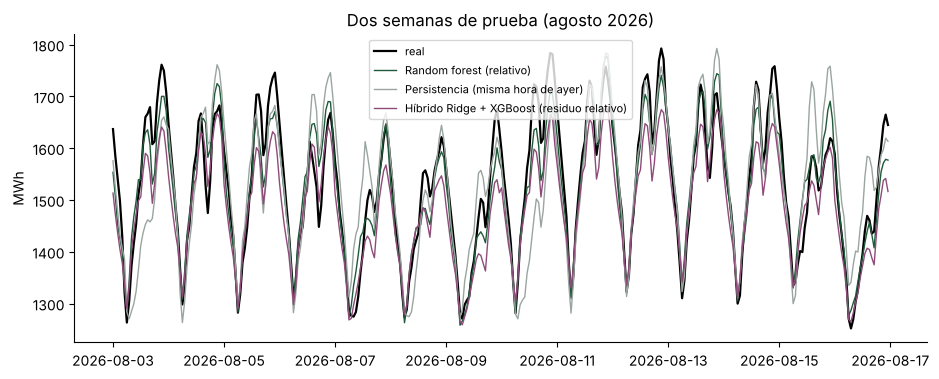

In [4]:
pt = pd.read_pickle(R + "pred_prueba.pkl"); s = pt["2026-08-03":"2026-08-16"]
fig, ax = plt.subplots(figsize=(11, 4)); ax.plot(s.index, s.y, color="k", lw=1.6, label="real")
for m in ["Random forest (relativo)", "Persistencia (misma hora de ayer)", "Híbrido Ridge + XGBoost (residuo relativo)"]: ax.plot(s.index, s[m], lw=1, label=m, color=COL[m])
ax.set_ylabel("MWh"); ax.set_title("Dos semanas de prueba (agosto 2026)"); ax.legend(fontsize=8); plt.show()

In [5]:
seg = pd.read_csv(R + "mape_por_segmento.csv"); print("MAPE (%) por tipo de día y por cuartil de calor:"); seg.round(2)

MAPE (%) por tipo de día y por cuartil de calor:


segmento,valor,n,Persistencia (misma hora de ayer),Estacional (misma hora semana pasada),Promedio por hora y día,Híbrido Ridge + XGBoost (residuo relativo),Random forest (relativo),Ridge (lineal),XGBoost (relativo)
tipo,festivo,768,5.110000,9.400000,10.760000,3.600000,3.720000,4.120000,3.480000
tipo,fin de semana,4.440,5.340000,5.180000,14.200000,3.170000,2.840000,3.320000,2.820000
tipo,laboral,10.464,3.870000,4.610000,14.820000,3.010000,2.330000,3.360000,2.360000
calor,frío,3.918,3.150000,4.240000,10.730000,2.640000,1.970000,2.870000,2.030000
calor,templado,3.918,3.980000,4.970000,14.410000,3.000000,2.420000,3.350000,2.380000
calor,caluroso,3.918,4.930000,5.250000,15.270000,3.310000,2.780000,3.640000,2.780000
calor,muy caluroso,3.918,5.310000,5.550000,17.370000,3.390000,3.010000,3.680000,3.000000


In [6]:
v1 = pd.read_csv("../resultados_v1/prueba.csv")[["modelo", "MAPE", "mejora_MSE_vs_Persistencia_%"]]
print("VERSIÓN 1 (árboles con la demanda en MWh) — prueba:"); v1.round(2)

VERSIÓN 1 (árboles con la demanda en MWh) — prueba:


modelo,MAPE,mejora_MSE_vs_Persistencia_%
Ridge (lineal),"3,38","45,3"
Híbrido (Ridge + XGBoost residual),"4,10","17,1"
Persistencia (misma hora de ayer),"4,34","0,0"
Estacional (misma hora semana pasada),"5,00","-29,4"
XGBoost,"4,96","-59,9"
Random forest,"6,35","-194,5"
Promedio por hora y día,"14,44","-722,0"


In [7]:
print("Sensibilidad ex-post (clima real del día pronosticado):"); pd.read_csv(R + "sensibilidad_expost.csv", index_col=0).round(3)

Sensibilidad ex-post (clima real del día pronosticado):


,MSE,RMSE,MAE,MAPE,AUC_pico,POD,FAR,CSI
Random forest (relativo),2.076,"45,56","32,45","2,43","0,977","0,907","0,091","0,831"
XGBoost (relativo),1.966,"44,34","31,17","2,34","0,978","0,917","0,091","0,840"
Ridge (lineal),4.731,"68,78","56,22","4,03","0,970","0,689","0,041","0,669"


 **Resultado.**

- **Se confirma el elegido:** el random forest relativo tiene MAPE de **2,54 %** y reduce el MSE **64 %** frente a la persistencia (IC 95 % por bootstrap de bloques de 7 días: 60–69 %), **72 %** frente a la misma hora de la semana pasada y **96 %** frente al promedio por hora y día. Las tres diferencias son significativas (Diebold-Mariano p < 0,001).
- Con el XGBoost relativo la diferencia no es significativa (p = 0,25): los dos árboles relativos son equivalentes. Al híbrido y a Ridge sí les gana (p < 0,001).
- **La lección de la versión 1:** con los árboles entrenados en MWh, el XGBoost tenía 60 % *más* error que la persistencia y el random forest 194 % más. El objetivo relativo cambió eso a 63 % y 64 % *menos*. Esa es la contribución metodológica del proyecto.
- La ventaja es mayor en días laborales (2,33 % contra 3,87 % de la persistencia) y se mantiene en los días más calurosos (3,01 % contra 5,31 %).
- Con el clima real del día pronosticado ("pronóstico del tiempo perfecto") el MAPE bajaría a 2,43 %: un pronóstico meteorológico bueno aportaría poco más.